In [1]:
import time
import numpy as np
import torch
from torch.func import grad, vjp, jvp, vmap, jacfwd, jacrev

# 自动检测：优先 CUDA，不可用则回退 CPU
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print("PyTorch 版本:", torch.__version__)
print("编译匹配的 CUDA 版本:", torch.version.cuda)   # 若显示 None，说明装成了 CPU 版 PyTorch
print("CUDA 是否可用:", torch.cuda.is_available())
print("当前选定设备:", device)

if torch.cuda.is_available():
    print("笔记本显卡型号:", torch.cuda.get_device_name(0))
    # 做一次实测运算，确认显卡驱动和 CUDA Kernel 工作正常
    a = torch.tensor([1.0, 2.0], device=device)
    b = torch.tensor([3.0, 4.0], device=device)
    print("GPU 实测点积 (预期 11.0):", (a @ b).item())

PyTorch 版本: 2.5.1+cu121
编译匹配的 CUDA 版本: 12.1
CUDA 是否可用: True
当前选定设备: cuda
笔记本显卡型号: NVIDIA GeForce RTX 3060 Laptop GPU
GPU 实测点积 (预期 11.0): 11.0


In [2]:
#小结1
def f(x):
    return torch.sum(x**2)/2

grad_f=grad(f)#touch中的梯度函数

x=torch.tensor([0.,1.,2.],device=device)
print('x    ',x)
print('fx:   ',f(x))
print('grad_f(x)  ',grad_f(x))

x     tensor([0., 1., 2.], device='cuda:0')
fx:    tensor(2.5000, device='cuda:0')
grad_f(x)   tensor([0., 1., 2.], device='cuda:0')


In [3]:
#lambda是定义函数的简写
f=lambda x:torch.sum(x**2)/2 #定义标量函数
x=torch.tensor([0.,1.,2.],device=device)

f_x,dfxT=vjp(f,x)#前向计算结果，计算x处的fx的值
#dfXT是torch给你生成一个拉回函数，对于偏f'w,此时还在等你在输出端给他一个种子w
dfxT_1=dfxT(torch.tensor(1.,device=device))#把输出端种子w=1传入vjp公式

print('x',x)
print('fx',f_x)
print('dfxT(1)',dfxT_1)

x tensor([0., 1., 2.], device='cuda:0')
fx tensor(2.5000, device='cuda:0')
dfxT(1) (tensor([0., 1., 2.], device='cuda:0'),)


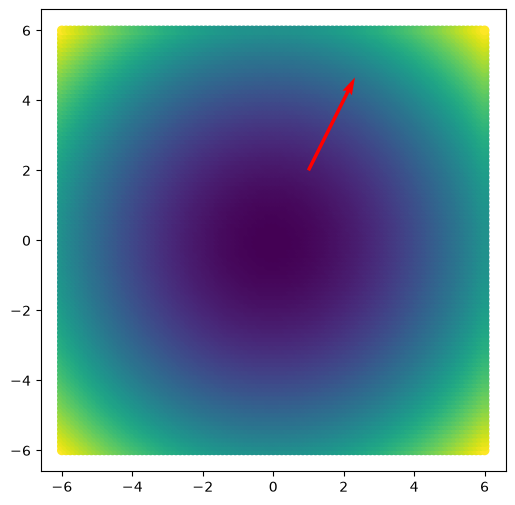

In [4]:
import matplotlib.pyplot as plt
# 在 [-6, 6] x [-6, 6] 上生成 101x101 均匀网格
xs1, xs2 = torch.meshgrid(
    torch.linspace(-6, 6, 101, device=device),
    torch.linspace(-6, 6, 101, device=device),
    indexing='xy'  # 与 numpy/jax 默认坐标排布一致
)
xs1 = xs1.reshape(101 ** 2, 1)
xs2 = xs2.reshape(101 ** 2, 1)
xs = torch.cat((xs1, xs2), dim=-1)  # 形状: (10201, 2)

# 用 vmap 一次性对所有 10201 个 2D 点批量求 f(x)
fs = vmap(f)(xs)

# matplotlib 只接受 CPU numpy 数组，因此 GPU 张量需要先 .cpu().numpy()
plt.figure(figsize=[6, 6])
plt.scatter(xs1.cpu().numpy(), xs2.cpu().numpy(), c=fs.cpu().numpy())
# 在点 (x[1], x[2]) = (1, 2) 处画出对应的梯度向量 (dfxT_1[0][1], dfxT_1[0][2]) = (1, 2)
plt.quiver(x[1].item(), x[2].item(),
           dfxT_1[0][1].item(), dfxT_1[0][2].item(),
           scale=10, color='r')
plt.show()